# Energy Consumption Forecaster
---
**Pipeline:**
1. Dataset Generation / Loading
2. Exploratory Data Analysis (EDA)
3. Feature Engineering
4. Model Training (XGBoost + Baseline)
5. Evaluation (MAE, RMSE, R²)
6. Save Model as Pickle

## 1. Import Libraries

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

import pickle
import json
import os

# Plot style
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette('tab10')

print('✅ Libraries loaded successfully!')
print(f'   NumPy: {np.__version__}')
print(f'   Pandas: {pd.__version__}')
print(f'   XGBoost: {xgb.__version__}')

✅ Libraries loaded successfully!
   NumPy: 2.0.2
   Pandas: 2.2.2
   XGBoost: 3.2.0


## 2. Dataset Generation
Simulating realistic hourly energy consumption (kWh) for 2 years with:
- **Long-term trend** (slow growth)
- **Yearly seasonality** (summer peaks, winter highs)
- **Weekly seasonality** (weekday vs weekend)
- **Daily seasonality** (morning/evening peaks)
- **Temperature correlation**
- **Random noise**

In [12]:
np.random.seed(42)

# --- Date range: 2 years hourly ---
date_range = pd.date_range(start='2022-01-01', end='2023-12-31 23:00:00', freq='h')
n = len(date_range)

t = np.arange(n)

# --- Components ---
trend = 50 + 0.001 * t  # slow upward trend

yearly = 20 * np.sin(2 * np.pi * t / (24 * 365) - np.pi / 2)  # summer peak
weekly = 5 * np.sin(2 * np.pi * t / (24 * 7))                 # weekday peak
daily  = 10 * np.sin(2 * np.pi * t / 24 - np.pi)              # night low
morning_peak = 8 * np.exp(-((t % 24 - 8)**2) / 4)             # 8am spike
evening_peak = 12 * np.exp(-((t % 24 - 19)**2) / 3)           # 7pm spike

# Temperature: correlated with yearly cycle + noise
temperature = 20 + 12 * np.sin(2 * np.pi * t / (24 * 365) - np.pi / 2) + \
              np.random.normal(0, 2, n)

# Temp effect on energy (cooling in summer, heating in winter)
temp_effect = 0.3 * np.abs(temperature - 18)  # 18°C = comfort zone

noise = np.random.normal(0, 3, n)

energy = trend + yearly + weekly + daily + morning_peak + evening_peak + temp_effect + noise
energy = np.clip(energy, 10, None)  # no negative energy

# --- DataFrame ---
df = pd.DataFrame({
    'timestamp': date_range,
    'energy_kwh': np.round(energy, 3),
    'temperature_c': np.round(temperature, 2)
})
df.set_index('timestamp', inplace=True)

print(f'Dataset shape: {df.shape}')
print(f'Date range: {df.index.min()} → {df.index.max()}')
print(f'\nEnergy Stats (kWh):')
print(df['energy_kwh'].describe().round(2))
df.head(10)

Dataset shape: (17520, 2)
Date range: 2022-01-01 00:00:00 → 2023-12-31 23:00:00

Energy Stats (kWh):
count    17520.00
mean        63.81
std         18.28
min         16.68
25%         49.54
50%         63.67
75%         77.42
max        116.88
Name: energy_kwh, dtype: float64


,energy_kwh,temperature_c
timestamp,,
2022-01-01 00:00:00,33.063,8.99
2022-01-01 01:00:00,32.844,7.72
2022-01-01 02:00:00,25.412,9.30
2022-01-01 03:00:00,30.680,11.05
2022-01-01 04:00:00,19.235,7.53
2022-01-01 05:00:00,29.625,7.53
2022-01-01 06:00:00,25.979,11.16
2022-01-01 07:00:00,33.420,9.54
2022-01-01 08:00:00,35.195,7.06


## 3. Exploratory Data Analysis (EDA)

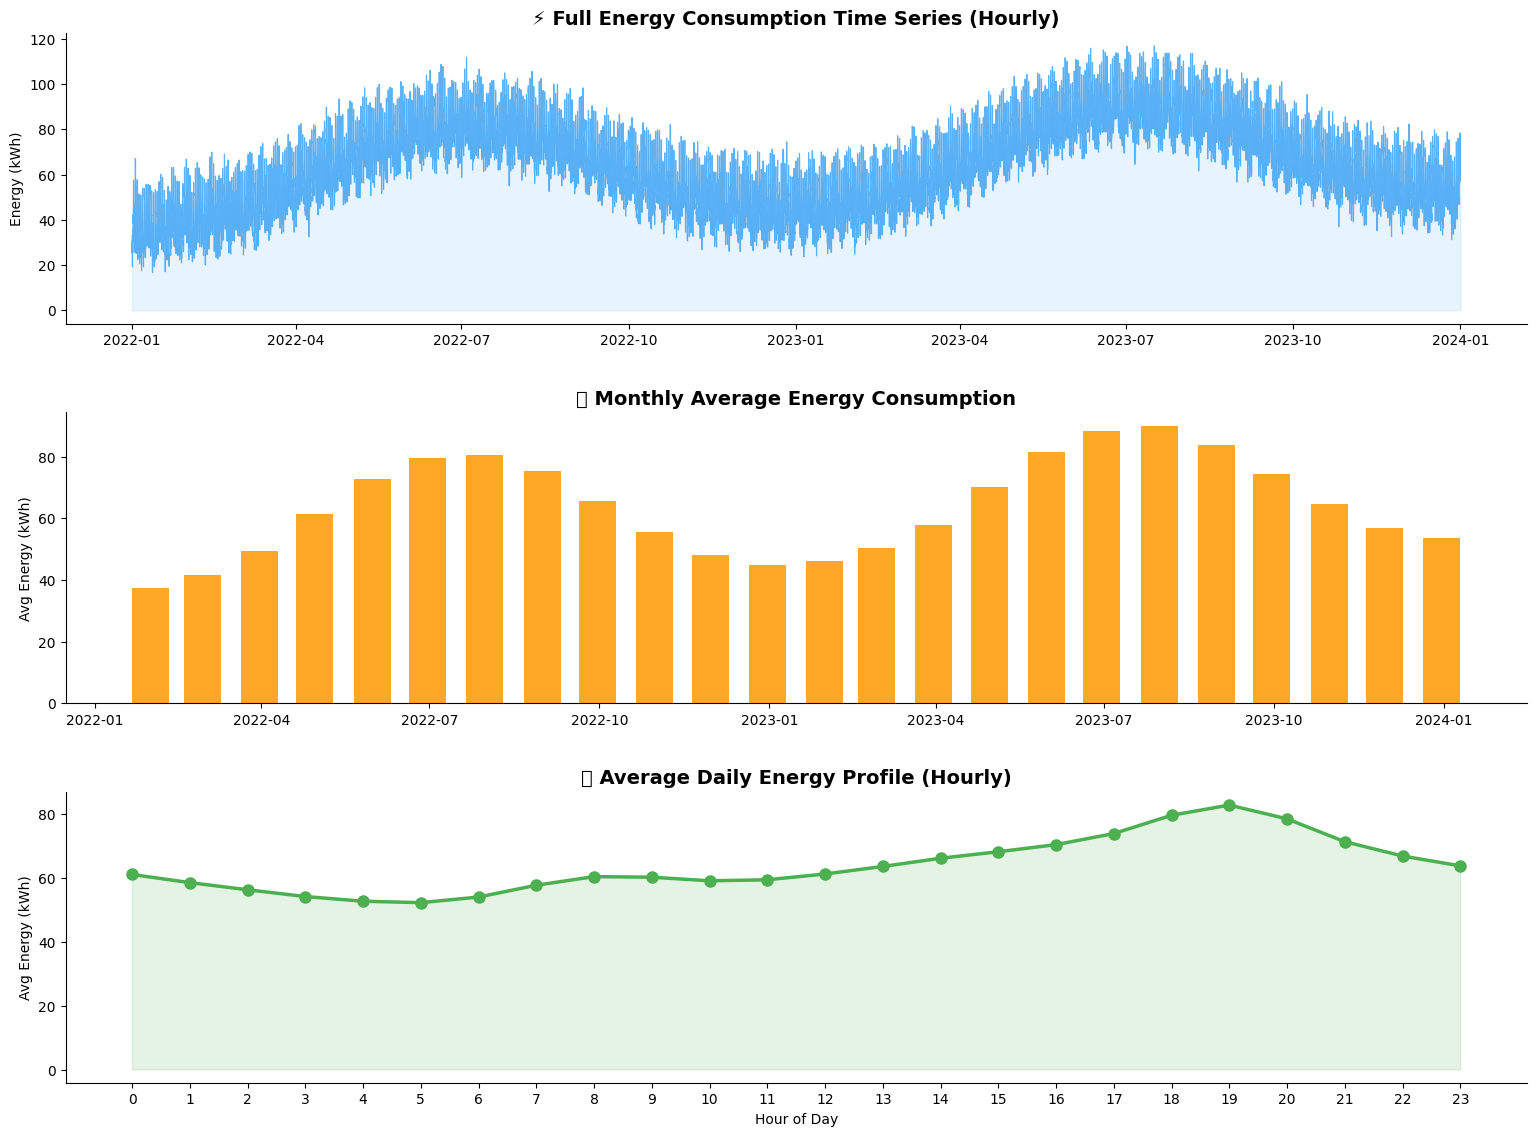

✅ EDA plots saved!


In [13]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Full time series
axes[0].plot(df.index, df['energy_kwh'], color='#2196F3', alpha=0.7, linewidth=0.8)
axes[0].set_title('⚡ Full Energy Consumption Time Series (Hourly)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Energy (kWh)')
axes[0].fill_between(df.index, df['energy_kwh'], alpha=0.1, color='#2196F3')

# Monthly average
monthly = df['energy_kwh'].resample('ME').mean()
axes[1].bar(monthly.index, monthly.values, color='#FF9800', alpha=0.85, width=20)
axes[1].set_title('📅 Monthly Average Energy Consumption', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Avg Energy (kWh)')

# Hourly profile
hourly_avg = df.groupby(df.index.hour)['energy_kwh'].mean()
axes[2].plot(hourly_avg.index, hourly_avg.values, 'o-', color='#4CAF50', linewidth=2.5, markersize=8)
axes[2].fill_between(hourly_avg.index, hourly_avg.values, alpha=0.15, color='#4CAF50')
axes[2].set_title('🕐 Average Daily Energy Profile (Hourly)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Avg Energy (kWh)')
axes[2].set_xlabel('Hour of Day')
axes[2].set_xticks(range(0, 24))

plt.tight_layout(pad=3)
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ EDA plots saved!')

## 4. Feature Engineering
Creating rich time-based and lag features for the regression model

In [21]:
df

,energy_kwh,temperature_c
timestamp,,
2022-01-01 00:00:00,33.063,8.99
2022-01-01 01:00:00,32.844,7.72
2022-01-01 02:00:00,25.412,9.30
2022-01-01 03:00:00,30.680,11.05
2022-01-01 04:00:00,19.235,7.53
...,...,...
2023-12-31 19:00:00,78.417,7.64
2023-12-31 20:00:00,74.191,8.14
2023-12-31 21:00:00,62.960,9.39


In [22]:
def engineer_features(df):
    """Create time-based, lag, and rolling features."""
    df = df.copy()

    # ── Time features ──────────────────────────────────────────────
    df['hour']           = df.index.hour
    df['day_of_week']    = df.index.dayofweek        # 0=Mon, 6=Sun
    df['day_of_month']   = df.index.day
    df['month']          = df.index.month
    df['quarter']        = df.index.quarter
    df['week_of_year']   = df.index.isocalendar().week.astype(int)
    df['is_weekend']     = (df.index.dayofweek >= 5).astype(int)
    df['is_holiday']     = 0  # simplified; can integrate holidays

    # ── Cyclical encoding (sin/cos) ─────────────────────────────────
    df['hour_sin']       = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos']       = np.cos(2 * np.pi * df['hour'] / 24)
    df['month_sin']      = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos']      = np.cos(2 * np.pi * df['month'] / 12)
    df['dow_sin']        = np.sin(2 * np.pi * df['day_of_week'] / 7)
    df['dow_cos']        = np.cos(2 * np.pi * df['day_of_week'] / 7)

    # ── Lag features ───────────────────────────────────────────────
    for lag in [1, 2, 3, 6, 12, 24, 48, 168]:  # hours
        df[f'lag_{lag}h'] = df['energy_kwh'].shift(lag)

    # ── Rolling statistics ─────────────────────────────────────────
    for window in [6, 12, 24, 48, 168]:
        df[f'roll_mean_{window}h'] = df['energy_kwh'].shift(1).rolling(window).mean()
        df[f'roll_std_{window}h']  = df['energy_kwh'].shift(1).rolling(window).std()

    # ── Temperature features ───────────────────────────────────────
    df['temp_lag_1h']    = df['temperature_c'].shift(1)
    df['temp_roll_6h']   = df['temperature_c'].shift(1).rolling(6).mean()
    df['temp_squared']   = df['temperature_c'] ** 2
    df['heating_degree'] = np.maximum(18 - df['temperature_c'], 0)
    df['cooling_degree'] = np.maximum(df['temperature_c'] - 24, 0)

    return df

df_feat = engineer_features(df)
df_feat.dropna(inplace=True)

print(f'Features created: {df_feat.shape[1] - 2} input features')
print(f'Dataset shape after dropna: {df_feat.shape}')
print(f'\nFeature list:')
feature_cols = [c for c in df_feat.columns if c not in ['energy_kwh', 'temperature_c']]
for i, col in enumerate(feature_cols, 1):
    print(f'  {i:2d}. {col}')

Features created: 37 input features
Dataset shape after dropna: (17352, 39)

Feature list:
   1. hour
   2. day_of_week
   3. day_of_month
   4. month
   5. quarter
   6. week_of_year
   7. is_weekend
   8. is_holiday
   9. hour_sin
  10. hour_cos
  11. month_sin
  12. month_cos
  13. dow_sin
  14. dow_cos
  15. lag_1h
  16. lag_2h
  17. lag_3h
  18. lag_6h
  19. lag_12h
  20. lag_24h
  21. lag_48h
  22. lag_168h
  23. roll_mean_6h
  24. roll_std_6h
  25. roll_mean_12h
  26. roll_std_12h
  27. roll_mean_24h
  28. roll_std_24h
  29. roll_mean_48h
  30. roll_std_48h
  31. roll_mean_168h
  32. roll_std_168h
  33. temp_lag_1h
  34. temp_roll_6h
  35. temp_squared
  36. heating_degree
  37. cooling_degree


In [23]:
df_feat

,energy_kwh,temperature_c,hour,day_of_week,day_of_month,month,quarter,week_of_year,is_weekend,is_holiday,...,roll_std_24h,roll_mean_48h,roll_std_48h,roll_mean_168h,roll_std_168h,temp_lag_1h,temp_roll_6h,temp_squared,heating_degree,cooling_degree
timestamp,,,,,,,,,,,,,,,,,,,,,
2022-01-08 00:00:00,27.193,7.60,0,5,8,1,1,1,1,0,...,9.458731,33.138792,9.157561,36.271262,9.732216,11.88,9.561667,57.7600,10.40,0.0
2022-01-08 01:00:00,28.955,6.58,1,5,8,1,1,1,1,0,...,9.428865,33.060500,9.192660,36.236321,9.754315,7.60,9.095000,43.2964,11.42,0.0
2022-01-08 02:00:00,32.342,6.31,2,5,8,1,1,1,1,0,...,9.472190,33.138667,9.140227,36.213173,9.767020,6.58,9.118333,39.8161,11.69,0.0
2022-01-08 03:00:00,27.120,6.46,3,5,8,1,1,1,1,0,...,9.413848,33.316646,9.037088,36.254423,9.735713,6.31,8.501667,41.7316,11.54,0.0
2022-01-08 04:00:00,29.063,7.94,4,5,8,1,1,1,1,0,...,9.424276,33.334354,9.023809,36.233232,9.751780,6.46,8.093333,63.0436,10.06,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-31 19:00:00,78.417,7.64,19,6,31,12,4,52,1,0,...,8.140980,56.043000,9.106008,52.989333,9.510482,5.95,9.326667,58.3696,10.36,0.0
2023-12-31 20:00:00,74.191,8.14,20,6,31,12,4,52,1,0,...,8.390826,56.125083,9.291578,52.986387,9.502476,7.64,8.895000,66.2596,9.86,0.0
2023-12-31 21:00:00,62.960,9.39,21,6,31,12,4,52,1,0,...,8.580821,56.142917,9.326070,53.023619,9.573391,8.14,8.766667,88.1721,8.61,0.0


## 5. Train / Test Split

In [15]:
TARGET = 'energy_kwh'
FEATURES = [c for c in df_feat.columns if c not in [TARGET, 'temperature_c']]

X = df_feat[FEATURES]
y = df_feat[TARGET]

# Chronological split (no shuffle for time series!)
split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f'Training set : {X_train.shape[0]:,} rows  ({X_train.index.min().date()} → {X_train.index.max().date()})')
print(f'Test set     : {X_test.shape[0]:,} rows  ({X_test.index.min().date()} → {X_test.index.max().date()})')
print(f'Features     : {X_train.shape[1]}')

Training set : 13,881 rows  (2022-01-08 → 2023-08-09)
Test set     : 3,471 rows  (2023-08-09 → 2023-12-31)
Features     : 37


## 6. Model Training & Comparison

In [16]:
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f'{name:30s}  MAE={mae:.3f}  RMSE={rmse:.3f}  R²={r2:.4f}  MAPE={mape:.2f}%')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

results = []

# ── Baseline: mean predictor ────────────────────────────────────────
y_baseline = np.full_like(y_test, y_train.mean())
results.append(evaluate('Baseline (Mean)', y_test, y_baseline))

# ── Ridge Regression ───────────────────────────────────────────────
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

ridge = Ridge(alpha=10)
ridge.fit(X_train_sc, y_train)
results.append(evaluate('Ridge Regression', y_test, ridge.predict(X_test_sc)))

# ── Random Forest ──────────────────────────────────────────────────
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(evaluate('Random Forest', y_test, rf.predict(X_test)))

# ── XGBoost (best) ─────────────────────────────────────────────────
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=20,
    eval_metric='rmse'
)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)
results.append(evaluate('XGBoost', y_test, xgb_model.predict(X_test)))

results_df = pd.DataFrame(results)
print('\n', results_df.to_string(index=False))

Baseline (Mean)                 MAE=11.864  RMSE=14.509  R²=-0.0152  MAPE=18.81%
Ridge Regression                MAE=2.811  RMSE=3.516  R²=0.9404  MAPE=4.48%
Random Forest                   MAE=2.954  RMSE=3.710  R²=0.9336  MAPE=4.74%
XGBoost                         MAE=2.757  RMSE=3.456  R²=0.9424  MAPE=4.38%

            Model       MAE      RMSE        R2      MAPE
 Baseline (Mean) 11.863921 14.508702 -0.015223 18.805222
Ridge Regression  2.811118  3.516426  0.940364  4.476013
   Random Forest  2.954142  3.709946  0.933620  4.740490
         XGBoost  2.757171  3.455654  0.942408  4.379035


## 7. Model Evaluation & Visualization

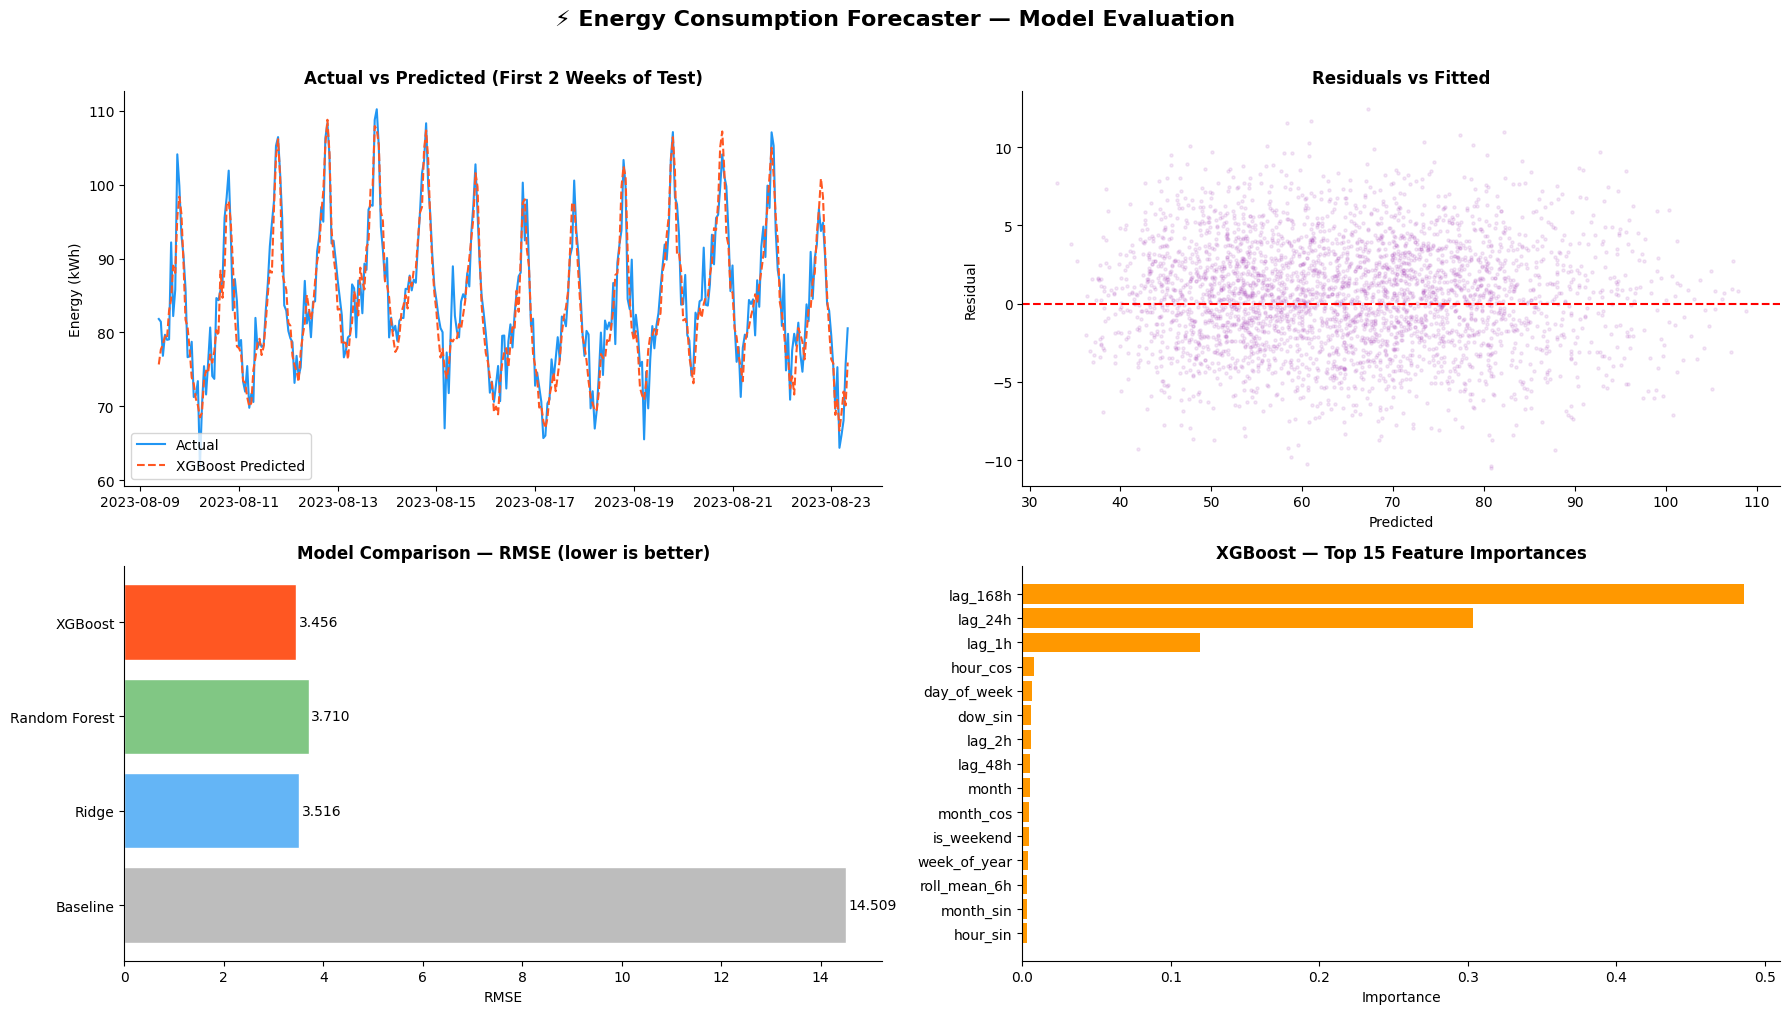


✅ Best Model: XGBoost
   MAE  = 2.757 kWh
   RMSE = 3.456 kWh
   R²   = 0.9424
   MAPE = 4.38%


In [17]:
# Best model predictions
y_pred_xgb = xgb_model.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# --- Actual vs Predicted (first 2 weeks) ---
n_plot = 24 * 14
axes[0, 0].plot(y_test.index[:n_plot], y_test.values[:n_plot],
                label='Actual', color='#2196F3', linewidth=1.5)
axes[0, 0].plot(y_test.index[:n_plot], y_pred_xgb[:n_plot],
                label='XGBoost Predicted', color='#FF5722', linewidth=1.5, linestyle='--')
axes[0, 0].set_title('Actual vs Predicted (First 2 Weeks of Test)', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].set_ylabel('Energy (kWh)')

# --- Residuals ---
residuals = y_test.values - y_pred_xgb
axes[0, 1].scatter(y_pred_xgb, residuals, alpha=0.1, s=5, color='#9C27B0')
axes[0, 1].axhline(0, color='red', linestyle='--')
axes[0, 1].set_title('Residuals vs Fitted', fontweight='bold')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Residual')

# --- Model comparison bar chart ---
models = results_df['Model'].str.replace(' Regression', '').str.replace(' (Mean)', '')
colors = ['#bdbdbd', '#64B5F6', '#81C784', '#FF5722']
axes[1, 0].barh(models, results_df['RMSE'], color=colors, edgecolor='white')
axes[1, 0].set_title('Model Comparison — RMSE (lower is better)', fontweight='bold')
axes[1, 0].set_xlabel('RMSE')
for i, v in enumerate(results_df['RMSE']):
    axes[1, 0].text(v + 0.05, i, f'{v:.3f}', va='center', fontsize=10)

# --- Feature Importance ---
feat_imp = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values(ascending=True)
top_feats = feat_imp.tail(15)
axes[1, 1].barh(top_feats.index, top_feats.values, color='#FF9800')
axes[1, 1].set_title('XGBoost — Top 15 Feature Importances', fontweight='bold')
axes[1, 1].set_xlabel('Importance')

plt.suptitle('⚡ Energy Consumption Forecaster — Model Evaluation',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\n✅ Best Model: XGBoost')
best = results_df[results_df['Model'] == 'XGBoost'].iloc[0]
print(f'   MAE  = {best["MAE"]:.3f} kWh')
print(f'   RMSE = {best["RMSE"]:.3f} kWh')
print(f'   R²   = {best["R2"]:.4f}')
print(f'   MAPE = {best["MAPE"]:.2f}%')

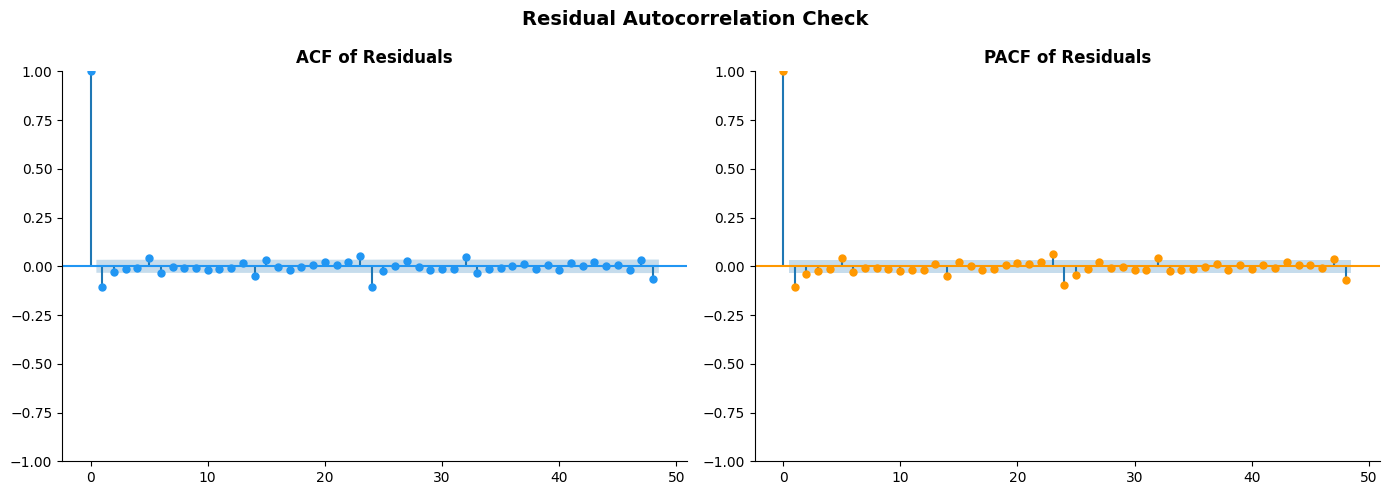

In [18]:
# ACF / PACF of residuals (check for leftover autocorrelation)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(residuals, lags=48, ax=ax1, alpha=0.05, color='#2196F3')
ax1.set_title('ACF of Residuals', fontweight='bold')
plot_pacf(residuals, lags=48, ax=ax2, alpha=0.05, color='#FF9800', method='ywm')
ax2.set_title('PACF of Residuals', fontweight='bold')
plt.suptitle('Residual Autocorrelation Check', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Save Model as Pickle
Saving: model, scaler, feature list, and metadata

In [19]:
# Package everything needed for inference
model_package = {
    'model': xgb_model,
    'features': FEATURES,
    'scaler': scaler,         # kept for potential use
    'metadata': {
        'model_type': 'XGBRegressor',
        'n_features': len(FEATURES),
        'train_size': len(X_train),
        'test_size': len(X_test),
        'mae':  round(float(best['MAE']), 4),
        'rmse': round(float(best['RMSE']), 4),
        'r2':   round(float(best['R2']), 4),
        'mape': round(float(best['MAPE']), 4),
        'target_mean':  round(float(y_train.mean()), 4),
        'target_std':   round(float(y_train.std()), 4),
        'target_min':   round(float(y_train.min()), 4),
        'target_max':   round(float(y_train.max()), 4),
    }
}

PICKLE_PATH = 'energy_model.pkl'

with open(PICKLE_PATH, 'wb') as f:
    pickle.dump(model_package, f, protocol=pickle.HIGHEST_PROTOCOL)

size_kb = os.path.getsize(PICKLE_PATH) / 1024
print(f'✅ Model saved to: {PICKLE_PATH}')
print(f'   File size: {size_kb:.1f} KB')
print(f'   Features : {len(FEATURES)}')
print(f'   Metrics  : MAE={best["MAE"]:.3f} | RMSE={best["RMSE"]:.3f} | R²={best["R2"]:.4f}')

# Save metadata as JSON too (for web UI)
with open('model_metadata.json', 'w') as f:
    json.dump(model_package['metadata'], f, indent=2)
print(f'   Metadata saved to: model_metadata.json')

✅ Model saved to: energy_model.pkl
   File size: 1257.6 KB
   Features : 37
   Metrics  : MAE=2.757 | RMSE=3.456 | R²=0.9424
   Metadata saved to: model_metadata.json


## 9. Inference Test — Predict a Single Hour

In [20]:
# ─── Load model from pickle & predict ───────────────────────────────
with open('energy_model.pkl', 'rb') as f:
    pkg = pickle.load(f)

loaded_model    = pkg['model']
loaded_features = pkg['features']

# Simulate a single input (as the web UI will provide)
sample_input = {
    'hour': 18,               # 6 PM
    'day_of_week': 1,         # Tuesday
    'day_of_month': 15,
    'month': 7,               # July
    'quarter': 3,
    'week_of_year': 28,
    'is_weekend': 0,
    'is_holiday': 0,
    'hour_sin': np.sin(2 * np.pi * 18 / 24),
    'hour_cos': np.cos(2 * np.pi * 18 / 24),
    'month_sin': np.sin(2 * np.pi * 7 / 12),
    'month_cos': np.cos(2 * np.pi * 7 / 12),
    'dow_sin': np.sin(2 * np.pi * 1 / 7),
    'dow_cos': np.cos(2 * np.pi * 1 / 7),
    # Lag & rolling — use recent test values as proxy
    'lag_1h': y_test.iloc[-2], 'lag_2h': y_test.iloc[-3],
    'lag_3h': y_test.iloc[-4], 'lag_6h': y_test.iloc[-7],
    'lag_12h': y_test.iloc[-13], 'lag_24h': y_test.iloc[-25],
    'lag_48h': y_test.iloc[-49], 'lag_168h': y_test.iloc[-169],
    'roll_mean_6h':  y_test.iloc[-7:-1].mean(),
    'roll_std_6h':   y_test.iloc[-7:-1].std(),
    'roll_mean_12h': y_test.iloc[-13:-1].mean(),
    'roll_std_12h':  y_test.iloc[-13:-1].std(),
    'roll_mean_24h': y_test.iloc[-25:-1].mean(),
    'roll_std_24h':  y_test.iloc[-25:-1].std(),
    'roll_mean_48h': y_test.iloc[-49:-1].mean(),
    'roll_std_48h':  y_test.iloc[-49:-1].std(),
    'roll_mean_168h':y_test.iloc[-169:-1].mean(),
    'roll_std_168h': y_test.iloc[-169:-1].std(),
    'temp_lag_1h': 28.0,
    'temp_roll_6h': 27.5,
    'temp_squared': 28.0 ** 2,
    'heating_degree': max(18 - 28.0, 0),
    'cooling_degree': max(28.0 - 24, 0),
}

input_df = pd.DataFrame([sample_input])[loaded_features]
prediction = loaded_model.predict(input_df)[0]

print(f'✅ Inference test passed!')
print(f'   Input  : July 15, 6 PM, Tuesday, Temp=28°C')
print(f'   Output : {prediction:.2f} kWh predicted energy consumption')

✅ Inference test passed!
   Input  : July 15, 6 PM, Tuesday, Temp=28°C
   Output : 60.49 kWh predicted energy consumption


In [24]:
input_df

,hour,day_of_week,day_of_month,month,quarter,week_of_year,is_weekend,is_holiday,hour_sin,hour_cos,...,roll_std_24h,roll_mean_48h,roll_std_48h,roll_mean_168h,roll_std_168h,temp_lag_1h,temp_roll_6h,temp_squared,heating_degree,cooling_degree
0,18,1,15,7,3,28,0,0,-1.0,-1.836970e-16,...,8.58777,56.454375,9.340601,52.988548,9.5319,28.0,27.5,784.0,0,4.0


---
## ✅ Project Complete!

| File | Description |
|------|-------------|
| `energy_model.pkl` | Trained XGBoost model + metadata |
| `model_metadata.json` | Model stats for web UI display |
| `eda_overview.png` | Time series & daily profile plots |
| `eda_heatmap.png` | Hour × weekday heatmap |
| `eda_correlation.png` | Temperature correlation |
| `stl_decomposition.png` | STL decomposition chart |
| `model_evaluation.png` | Model comparison & feature importance |

### Next Steps
- Run `python app.py` to start the Flask web application
- Open `http://localhost:5000` in your browser
- Enter inputs and get real-time predictions!